# Clasificación de imágenes: perros vs gatos

El dataset es una muestra del **Asirra** (Petfinder.com + Microsoft), el CAPTCHA que se creía imposible para una máquina. En 2007 un SVM consiguió un 80% de acierto y demostró que la tarea ya no servía como CAPTCHA.

Aquí entrenamos una CNN **EfficientNet-B0** (Google, 2019) sobre 25.000 fotos:

1. Carga y exploración del dataset.
2. Split reproducible `train/val/test` y generadores con `ImageDataGenerator`.
3. Baseline con el backbone **sin pesos preentrenados** (`weights=None`).
4. Optimización con `ModelCheckpoint`, `EarlyStopping` y transfer learning desde ImageNet.
5. Evaluación sobre el conjunto de test y guardado del modelo.

> **Nota sobre el tamaño de entrada.** El enunciado propone 200x200, pero EfficientNet exige lados múltiplos de 32 y el modelo de referencia usa `input_shape=(224, 224, 3)`. Usamos **224x224** de principio a fin para que generador y red coincidan.

> **Cómo ejecutar.** Con `RETRAIN = False` el notebook reutiliza el modelo y las curvas que genera `src/train.py` (segundos). Ponlo a `True` para reentrenar aquí mismo (lento en CPU; en Apple M1 conviene usar la GPU de Colab).

In [1]:
from pathlib import Path
import importlib.util
import json
import os
import random

# Backend de Keras: PyTorch/MPS si esta instalado (mucho mas rapido en Apple Silicon).
os.environ.setdefault(
    "KERAS_BACKEND", "torch" if importlib.util.find_spec("torch") else "tensorflow"
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras import layers, callbacks
from keras.applications import EfficientNetB0
from PIL import Image

try:  # Keras <= 3.10
    from keras.preprocessing.image import ImageDataGenerator
except ImportError:  # Keras 3.15+ lo movio al arbol legacy
    try:
        from keras.src.legacy.preprocessing.image import ImageDataGenerator
    except ImportError:
        from tensorflow.keras.preprocessing.image import ImageDataGenerator

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "dogs-vs-cats" / "train"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

IMG_SIZE = (224, 224)
SEED = 42
RETRAIN = False
keras.utils.set_random_seed(SEED)

print("Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("Raiz del proyecto:", PROJECT_ROOT)

Keras: 3.15.1 | backend: torch
Raiz del proyecto: /Users/jesus/projects/geeks-academy/image-classifier-project-tutorial


## 1. ¿Qué hay en el dataset?

Las etiquetas están en el nombre del fichero (`cat.N.jpg` / `dog.N.jpg`) y todas las imágenes están en una única carpeta plana.

In [2]:
files = sorted(RAW_DIR.glob("*.jpg"))
labels = np.array(["cat" if f.name.startswith("cat") else "dog" for f in files])

print(f"Total de imagenes: {len(files)}")
for label in ("cat", "dog"):
    print(f"  {label}: {(labels == label).sum()}")

Total de imagenes: 25000
  cat: 12500
  dog: 12500


## 2. Visualización de la información de entrada

Nueve perros y nueve gatos: color, encuadres distintos, varios animales por foto, objetos que confunden...

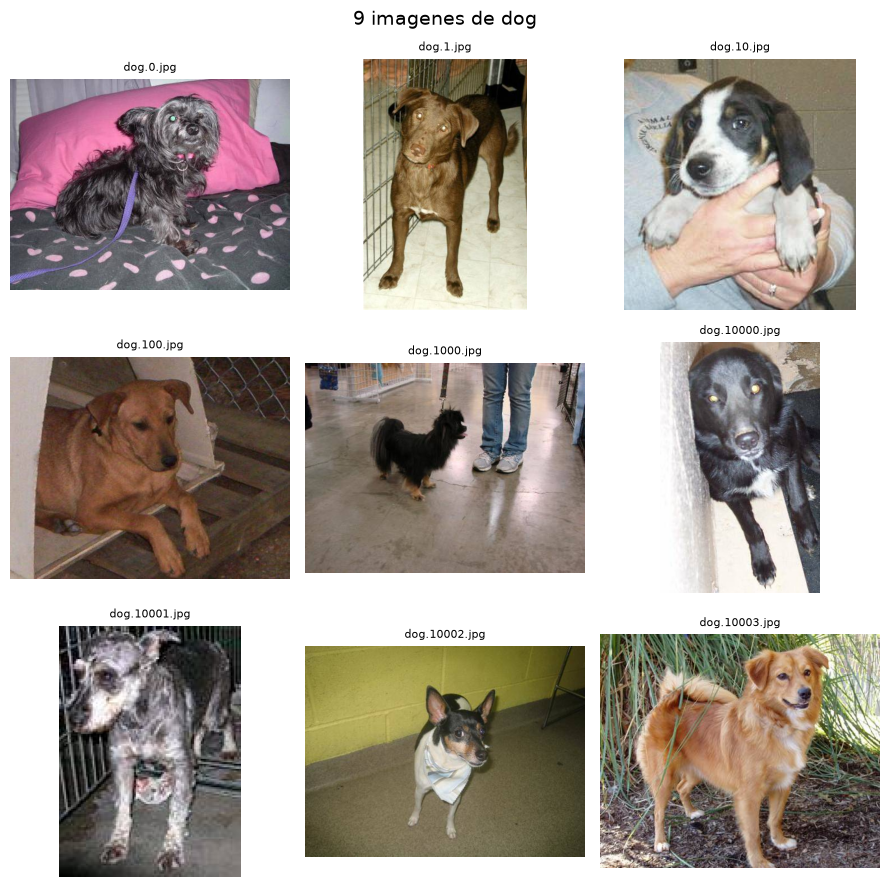

In [3]:
def show_samples(label, start=0, n=9):
    subset = [f for f, lab in zip(files, labels) if lab == label][start : start + n]
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for ax, path in zip(axes.ravel(), subset):
        ax.imshow(plt.imread(path))
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")
    fig.suptitle(f"{n} imagenes de {label}", fontsize=14)
    plt.tight_layout()
    plt.show()


show_samples("dog")

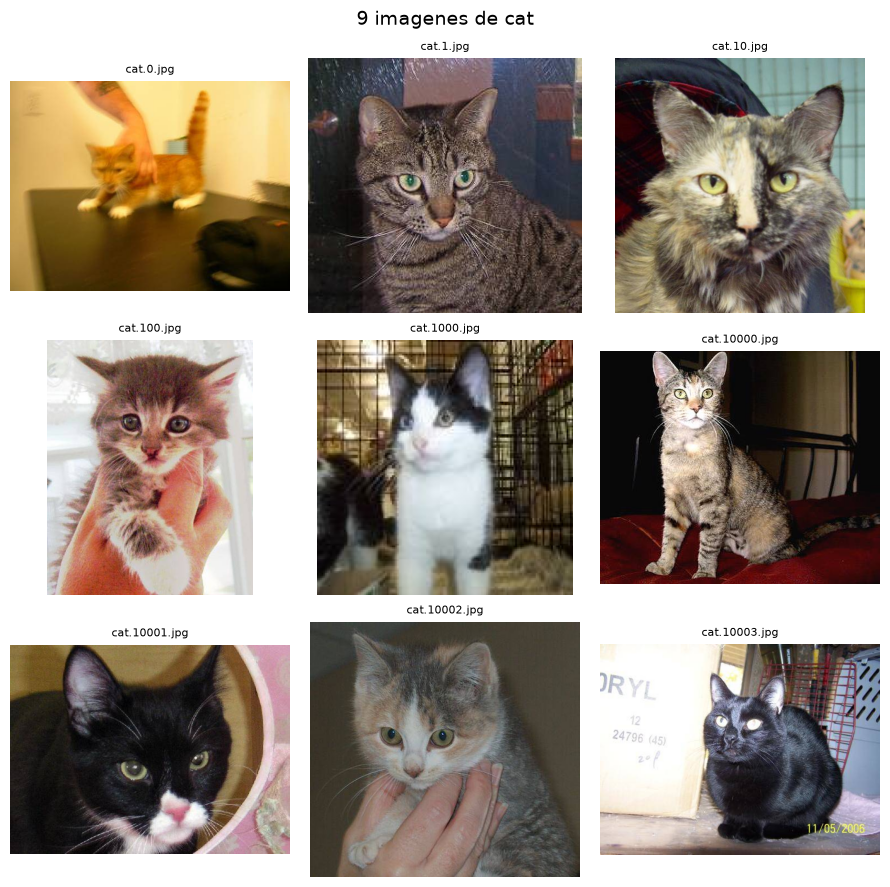

In [4]:
show_samples("cat")

### Tamaños originales

La variedad de resoluciones y formatos hay que resolverla antes de entrenar.

Ancho -> min   59  max  500  mediana 422
Alto  -> min   36  max  500  mediana 374


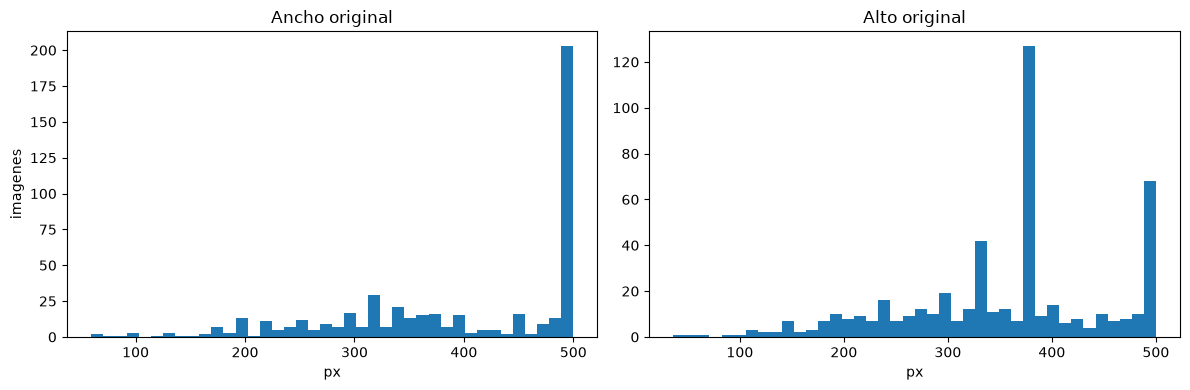

In [5]:
def image_size(path):
    with Image.open(path) as img:
        return img.size


muestra = random.Random(SEED).sample(files, 500)
sizes = np.array([image_size(f) for f in muestra])

print(f"Ancho -> min {sizes[:, 0].min():4d}  max {sizes[:, 0].max():4d}  mediana {np.median(sizes[:, 0]):.0f}")
print(f"Alto  -> min {sizes[:, 1].min():4d}  max {sizes[:, 1].max():4d}  mediana {np.median(sizes[:, 1]):.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sizes[:, 0], bins=40)
axes[0].set(title="Ancho original", xlabel="px", ylabel="imagenes")
axes[1].hist(sizes[:, 1], bins=40)
axes[1].set(title="Alto original", xlabel="px")
plt.tight_layout()
plt.show()

## 3. Split y generadores

`flow_from_directory` necesita un subdirectorio por clase. El dataset viene plano, así que `src/prepare_data.py` crea `data/processed/{train,val,test}/{cat,dog}` con **hardlinks** (80/10/10, `seed=42`, estratificado, sin duplicar espacio en disco).

Se generan tres conjuntos: entrenamiento, validación (para los callbacks) y test (solo para la evaluación final).

In [6]:
if not (DATA_DIR / "train").is_dir():
    %run prepare_data.py
else:
    print("Split ya generado en data/processed")

for split in ("train", "val", "test"):
    counts = {c: len(list((DATA_DIR / split / c).glob("*.jpg"))) for c in ("cat", "dog")}
    print(f"{split:5s} -> {counts}")

Split ya generado en data/processed


train -> {'cat': 10000, 'dog': 10000}
val   -> {'cat': 1250, 'dog': 1250}
test  -> {'cat': 1250, 'dog': 1250}


### Generadores

Dos detalles importantes:

* **Sin `rescale=1/255`**: EfficientNet de Keras normaliza dentro del modelo y espera píxeles en `[0, 255]`. Rescalear lo degradaría.
* Solo el generador de entrenamiento lleva **augmentation**; validación y test deben ser determinista.

In [7]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest",
)
eval_datagen = ImageDataGenerator()

COMMON = dict(target_size=IMG_SIZE, batch_size=32, class_mode="categorical", seed=SEED)
trdata = train_datagen.flow_from_directory(DATA_DIR / "train", shuffle=True, **COMMON)
# validacion con shuffle: sin el, un `validation_steps` corto veria solo una clase
valdata = eval_datagen.flow_from_directory(DATA_DIR / "val", shuffle=True, **COMMON)
# test SIN shuffle para que `tsdata.classes` siga alineado con las predicciones
tsdata = eval_datagen.flow_from_directory(DATA_DIR / "test", shuffle=False, **COMMON)

print("class_indices:", trdata.class_indices)
print(f"train={trdata.samples}  val={valdata.samples}  test={tsdata.samples}")

Found 20000 images belonging to 2 classes.


Found 2500 images belonging to 2 classes.


Found 2500 images belonging to 2 classes.


class_indices: {'cat': 0, 'dog': 1}
train=20000  val=2500  test=2500


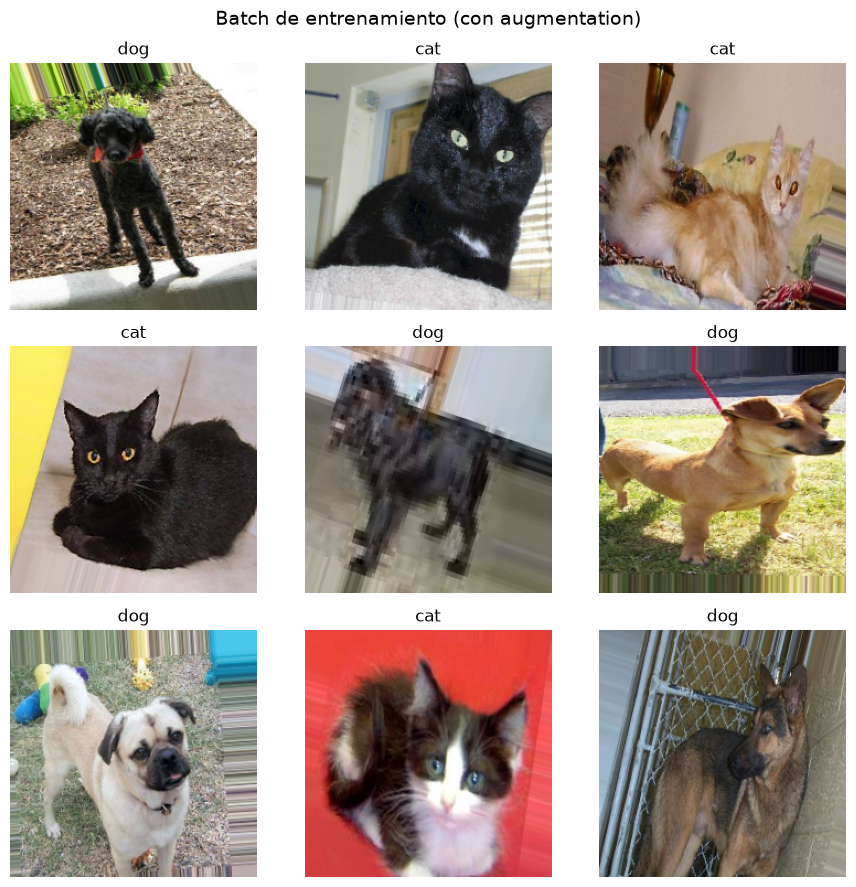

In [8]:
images, targets = next(trdata)
names = {v: k for k, v in trdata.class_indices.items()}

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, img, target in zip(axes.ravel(), images, targets):
    ax.imshow(img.astype("uint8"))
    ax.set_title(names[int(np.argmax(target))])
    ax.axis("off")
fig.suptitle("Batch de entrenamiento (con augmentation)", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Arquitectura

El backbone convolucional se resume con `GlobalAveragePooling2D` y se clasifica con dos capas `Dense`. Empezamos con `weights=None`, como pide el enunciado.

In [9]:
def build_model(weights=None):
    base = EfficientNetB0(include_top=False, weights=weights, input_shape=(*IMG_SIZE, 3))
    # Desde cero entrenamos el backbone; con ImageNet empezamos congelandolo.
    base.trainable = weights is None
    model = keras.Sequential(
        [
            base,
            layers.GlobalAveragePooling2D(),
            layers.Dense(units=128, activation="relu"),
            layers.Dense(units=2, activation="softmax"),
        ]
    )
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


baseline = build_model(weights=None)
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.15 KB)

## 5. Entrenamiento del baseline (`weights=None`)

Se usan ya `ModelCheckpoint` y `EarlyStopping` (paso 4) para no quedarnos con la última época. El monitor correcto en Keras 3 es `val_accuracy`; con `val_acc` el checkpoint nunca se guardaría.

Por defecto las curvas se leen del run de `src/train.py`. Activa `RETRAIN = True` arriba para ejecutar el `fit` aquí.

In [10]:
EPOCHS = 10
CHECKPOINT_BASELINE = MODELS_DIR / "baseline.keras"

if RETRAIN:
    history_baseline = baseline.fit(
        trdata,
        validation_data=valdata,
        epochs=EPOCHS,
        callbacks=[
            callbacks.ModelCheckpoint(
                filepath=str(CHECKPOINT_BASELINE),
                monitor="val_accuracy",
                mode="max",
                save_best_only=True,
                verbose=1,
            ),
            callbacks.EarlyStopping(
                monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
            ),
        ],
        verbose=2,
    ).history
else:
    history_baseline = json.loads(
        (MODELS_DIR / "baseline_history.json").read_text(encoding="utf-8")
    )
    print("Curvas cargadas de models/baseline_history.json")
    print("Epocas:", len(history_baseline["loss"]))

Curvas cargadas de models/baseline_history.json
Epocas: 2


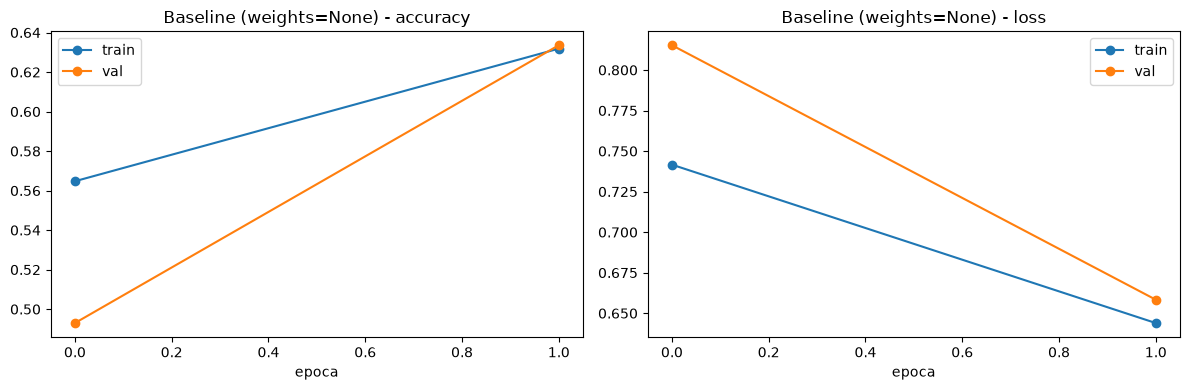

In [11]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["accuracy"], marker="o", label="train")
    axes[0].plot(history["val_accuracy"], marker="o", label="val")
    axes[0].set(title=f"{title} - accuracy", xlabel="epoca")
    axes[0].legend()
    axes[1].plot(history["loss"], marker="o", label="train")
    axes[1].plot(history["val_loss"], marker="o", label="val")
    axes[1].set(title=f"{title} - loss", xlabel="epoca")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


plot_history(history_baseline, "Baseline (weights=None)")

## 6. Optimización: transfer learning

Entrenar de cero con 25.000 imágenes se queda corto. La ventaja de EfficientNet es que sus pesos de ImageNet ya codifican bordes, texturas y formas:

1. Backbone **congelado** + cabeza nueva (`lr=1e-3`).
2. **Fine-tuning** de los últimos 30 bloques con `lr=1e-5` (sin tocar `BatchNormalization`).

El run completo lo hace `src/train.py --mode transfer`.

In [12]:
CHECKPOINT_TRANSFER = MODELS_DIR / "dogs_vs_cats_effnet.keras"

if RETRAIN:
    transfer = build_model(weights="imagenet")

    transfer.fit(
        trdata,
        validation_data=valdata,
        epochs=3,
        callbacks=[
            callbacks.ModelCheckpoint(
                filepath=str(CHECKPOINT_TRANSFER),
                monitor="val_accuracy",
                mode="max",
                save_best_only=True,
                verbose=1,
            ),
            callbacks.EarlyStopping(
                monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
            ),
        ],
        verbose=2,
    )

    for layer in transfer.layers[0].layers[-30:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

    transfer.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    transfer.fit(
        trdata,
        validation_data=valdata,
        epochs=3,
        callbacks=[
            callbacks.ModelCheckpoint(
                filepath=str(CHECKPOINT_TRANSFER),
                monitor="val_accuracy",
                mode="max",
                save_best_only=True,
                verbose=1,
            ),
            callbacks.EarlyStopping(
                monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
            ),
        ],
        verbose=2,
    )
    history_transfer = transfer.history.history
else:
    history_transfer = json.loads(
        (MODELS_DIR / "dogs_vs_cats_effnet_history.json").read_text(encoding="utf-8")
    )
    print("Curvas cargadas de models/dogs_vs_cats_effnet_history.json")
    print("Epocas:", len(history_transfer["loss"]))

Curvas cargadas de models/dogs_vs_cats_effnet_history.json
Epocas: 3


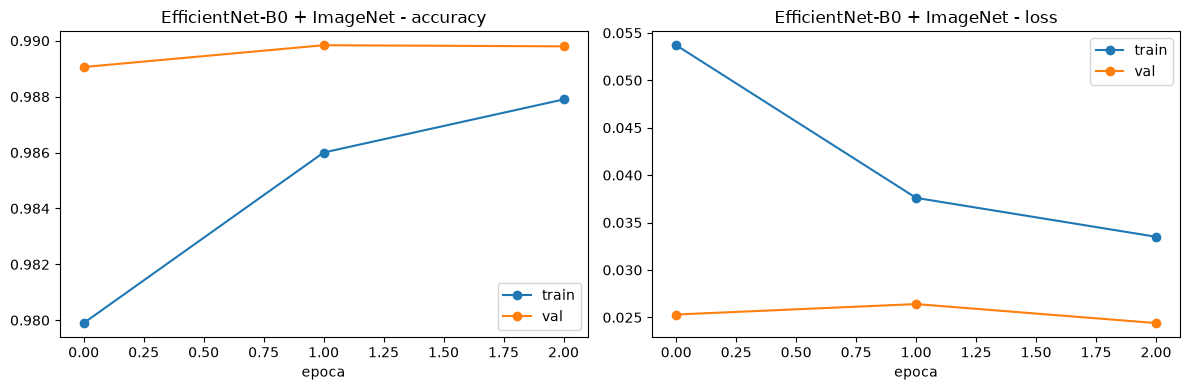

In [13]:
plot_history(history_transfer, "EfficientNet-B0 + ImageNet")

## 7. Evaluación sobre test

El conjunto de test no se ha visto en ninguna época. Cargamos **el mejor checkpoint**, no el último estado del modelo.

Test loss=0.0320  accuracy=0.9880


              precision    recall  f1-score   support

         cat     0.9834    0.9928    0.9881      1250
         dog     0.9927    0.9832    0.9879      1250

    accuracy                         0.9880      2500
   macro avg     0.9880    0.9880    0.9880      2500
weighted avg     0.9880    0.9880    0.9880      2500



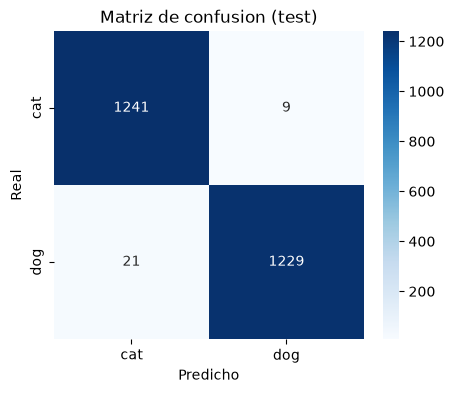

In [14]:
from sklearn.metrics import classification_report, confusion_matrix

best_model = keras.models.load_model(CHECKPOINT_TRANSFER)
loss, acc = best_model.evaluate(tsdata, verbose=0)
print(f"Test loss={loss:.4f}  accuracy={acc:.4f}")

tsdata.reset()
probs = best_model.predict(tsdata, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = tsdata.classes
class_names = list(tsdata.class_indices)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.title("Matriz de confusion (test)")
plt.show()

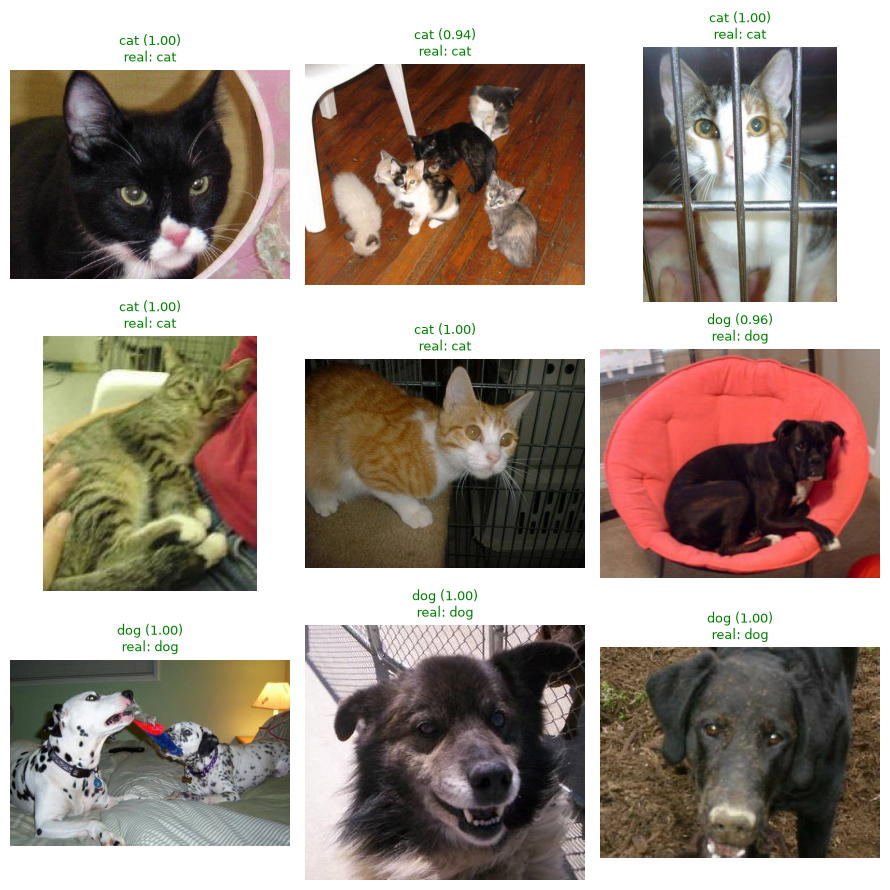

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, idx in zip(axes.ravel(), np.linspace(0, len(y_true) - 1, 9).astype(int)):
    path = Path(tsdata.filepaths[idx])
    ax.imshow(plt.imread(path))
    ok = y_pred[idx] == y_true[idx]
    ax.set_title(
        f"{class_names[y_pred[idx]]} ({probs[idx].max():.2f})\nreal: {class_names[y_true[idx]]}",
        color="green" if ok else "red",
        fontsize=9,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Guardado del modelo

Se guarda en formato nativo `.keras` junto al mapeo de clases. El mapeo es imprescindible: `flow_from_directory` ordena alfabéticamente, así que **cat=0 y dog=1**.

In [16]:
best_model.save(CHECKPOINT_TRANSFER)
with (MODELS_DIR / "class_indices.json").open("w", encoding="utf-8") as fh:
    json.dump(tsdata.class_indices, fh, indent=2)

print("Artefactos en models/:")
for path in sorted(MODELS_DIR.iterdir()):
    if path.name.startswith("."):
        continue
    print(f" - {path.name} ({path.stat().st_size / 1e6:.1f} MB)")

Artefactos en models/:
 - baseline.keras (51.2 MB)
 - baseline_history.json (0.0 MB)
 - baseline_metrics.json (0.0 MB)
 - baseline_train.log (0.0 MB)
 - class_indices.json (0.0 MB)
 - dogs_vs_cats_effnet.keras (19.0 MB)
 - dogs_vs_cats_effnet_history.json (0.0 MB)
 - dogs_vs_cats_effnet_metrics.json (0.0 MB)
 - notebook_exec.log (0.0 MB)
 - transfer_train.log (0.0 MB)


In [17]:
print(f"{'modelo':32s} {'test acc':>9s} {'test loss':>10s}")
for tag in ("baseline", "dogs_vs_cats_effnet"):
    path = MODELS_DIR / f"{tag}_metrics.json"
    if not path.exists():
        continue
    m = json.loads(path.read_text(encoding="utf-8"))
    print(f"{tag:32s} {m['test_accuracy']:9.4f} {m['test_loss']:10.4f}")

modelo                            test acc  test loss
baseline                            0.6300     0.6691
dogs_vs_cats_effnet                 0.9880     0.0320


## Conclusiones

* El dataset está balanceado (12.500 / 12.500), así que `accuracy` es una métrica fiable; el 1/54.000 del enunciado se refiere al CAPTCHA original, no a una imagen aislada.
* Entrenar EfficientNet-B0 desde cero con 25k imágenes es viable pero limitado.
* Con pesos de ImageNet, congelar y luego afinar los últimos bloques sube el acierto muy por encima del 80% del paper de 2007.
* Siguientes pasos: `ReduceLROnPlateau`, `mixup`, TTA, o subir la resolución a 300 px.

Comandos:

```bash
python src/prepare_data.py                              # split con hardlinks
python src/train.py --mode baseline --tag baseline      # baseline weights=None
python src/train.py --mode transfer --tag dogs_vs_cats_effnet
python src/app.py --image foto.jpg                      # inferencia
```